In [1]:
import geopandas as gpd
import pandas as pd
from pathlib import Path

In [27]:
RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
list(RAW.iterdir())

[PosixPath('../data/raw/Agregados_por_setores_renda_responsavel_BR.csv'),
 PosixPath('../data/raw/GO_setores_CD2022.gpkg')]

In [3]:
sectors = gpd.read_file(RAW / "GO_setores_CD2022.gpkg")
sectors.shape

(12861, 30)

In [5]:
sectors.columns

Index(['CD_SETOR', 'SITUACAO', 'CD_SIT', 'CD_TIPO', 'AREA_KM2', 'CD_REGIAO',
       'NM_REGIAO', 'CD_UF', 'NM_UF', 'CD_MUN', 'NM_MUN', 'CD_DIST', 'NM_DIST',
       'CD_SUBDIST', 'NM_SUBDIST', 'CD_BAIRRO', 'NM_BAIRRO', 'CD_NU', 'NM_NU',
       'CD_FCU', 'NM_FCU', 'CD_AGLOM', 'NM_AGLOM', 'CD_RGINT', 'NM_RGINT',
       'CD_RGI', 'NM_RGI', 'CD_CONCURB', 'NM_CONCURB', 'geometry'],
      dtype='str')

In [6]:
sectors.head()

,CD_SETOR,SITUACAO,CD_SIT,CD_TIPO,AREA_KM2,CD_REGIAO,NM_REGIAO,CD_UF,NM_UF,CD_MUN,...,NM_FCU,CD_AGLOM,NM_AGLOM,CD_RGINT,NM_RGINT,CD_RGI,NM_RGI,CD_CONCURB,NM_CONCURB,geometry
0,520005005000001,Urbana,1,0,0.153902,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43793 -16.75877, -49.43848 -16.7..."
1,520005005000002,Urbana,1,0,0.314781,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43754 -16.75932, -49.43793 -16.7..."
2,520005005000003,Urbana,1,0,0.201200,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43525 -16.76401, -49.43526 -16.7..."
3,520005005000004,Urbana,1,0,0.204826,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.42468 -16.76712, -49.42479 -16.7..."
4,520005005000005,Rural,8,0,31.387504,5,Centro-Oeste,52,Goiás,5200050,...,NaN,NaN,NaN,5201,Goiânia,520001,Goiânia,5208707,Goiânia/GO,"POLYGON ((-49.43754 -16.86015, -49.43849 -16.8..."


In [7]:
sectors.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 12861 entries, 0 to 12860
Data columns (total 30 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   CD_SETOR    12861 non-null  str     
 1   SITUACAO    12859 non-null  str     
 2   CD_SIT      12861 non-null  str     
 3   CD_TIPO     12861 non-null  str     
 4   AREA_KM2    12861 non-null  float64 
 5   CD_REGIAO   12861 non-null  str     
 6   NM_REGIAO   12861 non-null  str     
 7   CD_UF       12861 non-null  str     
 8   NM_UF       12861 non-null  str     
 9   CD_MUN      12861 non-null  str     
 10  NM_MUN      12861 non-null  str     
 11  CD_DIST     12861 non-null  str     
 12  NM_DIST     12861 non-null  str     
 13  CD_SUBDIST  12861 non-null  str     
 14  NM_SUBDIST  2302 non-null   str     
 15  CD_BAIRRO   85 non-null     str     
 16  NM_BAIRRO   85 non-null     str     
 17  CD_NU       255 non-null    str     
 18  NM_NU       255 non-null    str     
 

In [9]:
sectors.crs

<Geographic 2D CRS: EPSG:4674>
Name: SIRGAS 2000
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: Latin America - Central America and South America - onshore and offshore. Brazil - onshore and offshore.
- bounds: (-122.19, -59.87, -25.28, 32.72)
Datum: Sistema de Referencia Geocentrico para las AmericaS 2000
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [10]:
sectors["CD_MUN"].head()

0    5200050
1    5200050
2    5200050
3    5200050
4    5200050
Name: CD_MUN, dtype: str

In [11]:
goiania_sectors = sectors[sectors["CD_MUN"] == "5208707"].copy()
goiania_sectors.shape

(2310, 30)

In [13]:
goiania_sectors["NM_MUN"].unique()

<StringArray>
['Goiânia']
Length: 1, dtype: str

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

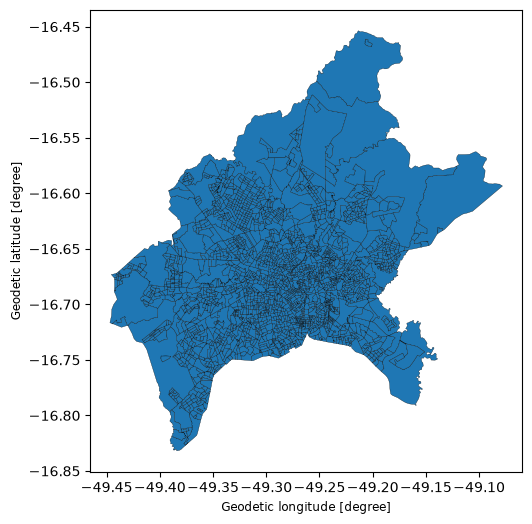

In [14]:
goiania_sectors.plot(figsize=(6, 6), edgecolor="black", linewidth=0.2)

In [15]:
goiania_sectors["SITUACAO"].value_counts()

SITUACAO
Urbana    2291
Rural       19
Name: count, dtype: int64

In [16]:
goiania_sectors["CD_TIPO"].value_counts()

CD_TIPO
0    2199
1      86
4      15
7       5
3       3
6       1
2       1
Name: count, dtype: int64

In [17]:
goiania_sectors["AREA_KM2"].describe()

count    2310.000000
mean        0.315713
std         1.949129
min         0.000846
25%         0.060883
50%         0.106466
75%         0.180868
max        46.986975
Name: AREA_KM2, dtype: float64

In [18]:
goiania_sectors.nlargest(5, "AREA_KM2")[["CD_SETOR", "SITUACAO", "AREA_KM2"]]

,CD_SETOR,SITUACAO,AREA_KM2
6624,520870705630134,Rural,46.986975
6618,520870705630128,Rural,37.444661
6630,520870715000002,Rural,36.793405
6635,520870715000008,Rural,30.710308
6626,520870705630136,Rural,27.650357


In [19]:
goiania_sectors.nsmallest(5, "AREA_KM2")[["CD_SETOR", "SITUACAO", "AREA_KM2"]]

,CD_SETOR,SITUACAO,AREA_KM2
5097,520870705200050,Urbana,0.000846
4610,520870705090050,Urbana,0.001693
4367,520870705010041,Urbana,0.002813
4761,520870705130065,Urbana,0.003174
4790,520870705130094,Urbana,0.003511


#### Os maiores setores são rurais. Necessidade de decidir o que fazer com os rurais
#### Os menores são urbanos e minúsculos. 

In [21]:
one_pixel = 0.0009   # 30 m x 30 m, em km²
thermal_pixel = 0.01 # 100 m x 100 m, em km²

(goiania_sectors["AREA_KM2"] < one_pixel).sum()

np.int64(1)

In [23]:
(goiania_sectors["AREA_KM2"] < thermal_pixel).sum()

np.int64(49)

In [ ]:
# Marcando os setores rurais  (análise principal roda só nos urbanos)
goiania_sectors["is_rural"] = goiania_sectors["SITUACAO"] == "Rural"

In [25]:
goiania_sectors["small_sector"] = goiania_sectors["AREA_KM2"] < thermal_pixel

In [28]:
goiania_sectors.to_file(PROCESSED / "goiania_sectors.gpkg", driver="GPKG")